# Explore the Burgers equation dataset

This notebook lets you inspect and visualize the simulated data for ESE 4020 Topic 12. Each row of **X** is an initial condition \(u(x,0)\), and the corresponding row of **Y** is its numerical solution \(u(x,0.25)\). There are 64 sampled spatial positions per function.

**Experiment rule:** We only load `data/train.npz` here. Leave `data/test_locked.npz` untouched until the final evaluation. Run cells from top to bottom, then change the editable parameters and rerun them.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

# The notebook normally lives directly inside burgers_operator_checkpoint/.
data_path = Path('data/train.npz')
if not data_path.exists():
    data_path = Path('burgers_operator_checkpoint/data/train.npz')
if not data_path.exists():
    raise FileNotFoundError('Put this notebook inside the project folder, next to data/.')

with np.load(data_path) as data:
    print('Available arrays:', data.files)
    X = data['X'].copy()
    Y = data['Y'].copy()
    x = data['x'].copy()
    a = data['a'].copy()
    b = data['b'].copy()
    sample_ids = data['sample_id'].copy()

print(f'X: {X.shape}, Y: {Y.shape}, x: {x.shape}')
print(f'{len(X)} independent training functions, each sampled at {len(x)} points')

Available arrays: ['X', 'Y', 'a', 'b', 'x', 'sample_id']
X: (800, 64), Y: (800, 64), x: (64,)
800 independent training functions, each sampled at 64 points


## 1. Look at the actual numbers

The same row index in `X` and `Y` refers to the same initial condition and its evolved solution. Change `pair_index` to inspect a different example.

In [2]:
pair_index = 0  # Change this from 0 to 799
assert 0 <= pair_index < len(X)
pair_table = pd.DataFrame({
    'x': x,
    'initial_u(x,0)': X[pair_index],
    'solution_u(x,0.25)': Y[pair_index],
    'change': Y[pair_index] - X[pair_index],
})
print('Original sample ID:', sample_ids[pair_index])
print('Sine coefficients a:', np.round(a[pair_index], 3))
print('Cosine coefficients b:', np.round(b[pair_index], 3))
display(pair_table.head(10))
# Optional: pair_table.to_csv('one_training_pair.csv', index=False)

Original sample ID: 560
Sine coefficients a: [-0.04  -0.808 -0.329  1.01   1.608]
Cosine coefficients b: [ 0.545 -0.174  1.747 -0.013  0.685]


,x,"initial_u(x,0)","solution_u(x,0.25)",change
0,0.000000,0.293523,0.168471,-0.125051
1,0.015625,0.316421,0.165989,-0.150432
2,0.031250,0.308640,0.156769,-0.151871
3,0.046875,0.265749,0.138788,-0.126962
4,0.062500,0.189841,0.111072,-0.078769
5,0.078125,0.089429,0.074836,-0.014593
6,0.093750,-0.021992,0.034117,0.056109
7,0.109375,-0.128429,-0.004963,0.123466
8,0.125000,-0.214392,-0.036152,0.178240
9,0.140625,-0.267773,-0.055952,0.211821


## 2. Plot any initial condition and its solution

The periodic grid excludes \(x=1\), so we append the first value at the right edge when drawing a continuous-looking periodic curve. Change the index or toggle the displayed curves.

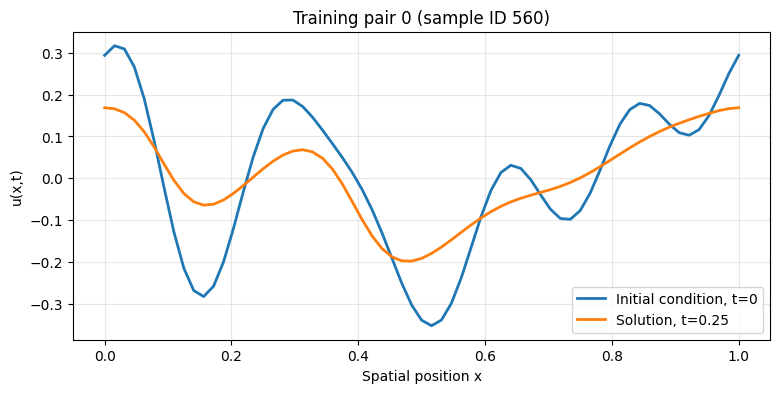

In [3]:
def plot_pair(index=0, show_initial=True, show_solution=True, show_change=False):
    if not 0 <= index < len(X):
        raise IndexError(f'index must be between 0 and {len(X)-1}')
    xp = np.r_[x, 1.0]  # append periodic endpoint for display
    fig, ax = plt.subplots(figsize=(9, 4))
    if show_initial:
        ax.plot(xp, np.r_[X[index], X[index, 0]], label='Initial condition, t=0', lw=2)
    if show_solution:
        ax.plot(xp, np.r_[Y[index], Y[index, 0]], label='Solution, t=0.25', lw=2)
    if show_change:
        delta = Y[index] - X[index]
        ax.plot(xp, np.r_[delta, delta[0]], label='Solution - initial', ls='--')
    ax.set(title=f'Training pair {index} (sample ID {sample_ids[index]})',
           xlabel='Spatial position x', ylabel='u(x,t)')
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

plot_pair(index=pair_index, show_change=False)

## 3. Compare several different functions

Choose how many training pairs to inspect. Because the random seed is fixed, you can reproduce the same set of examples.

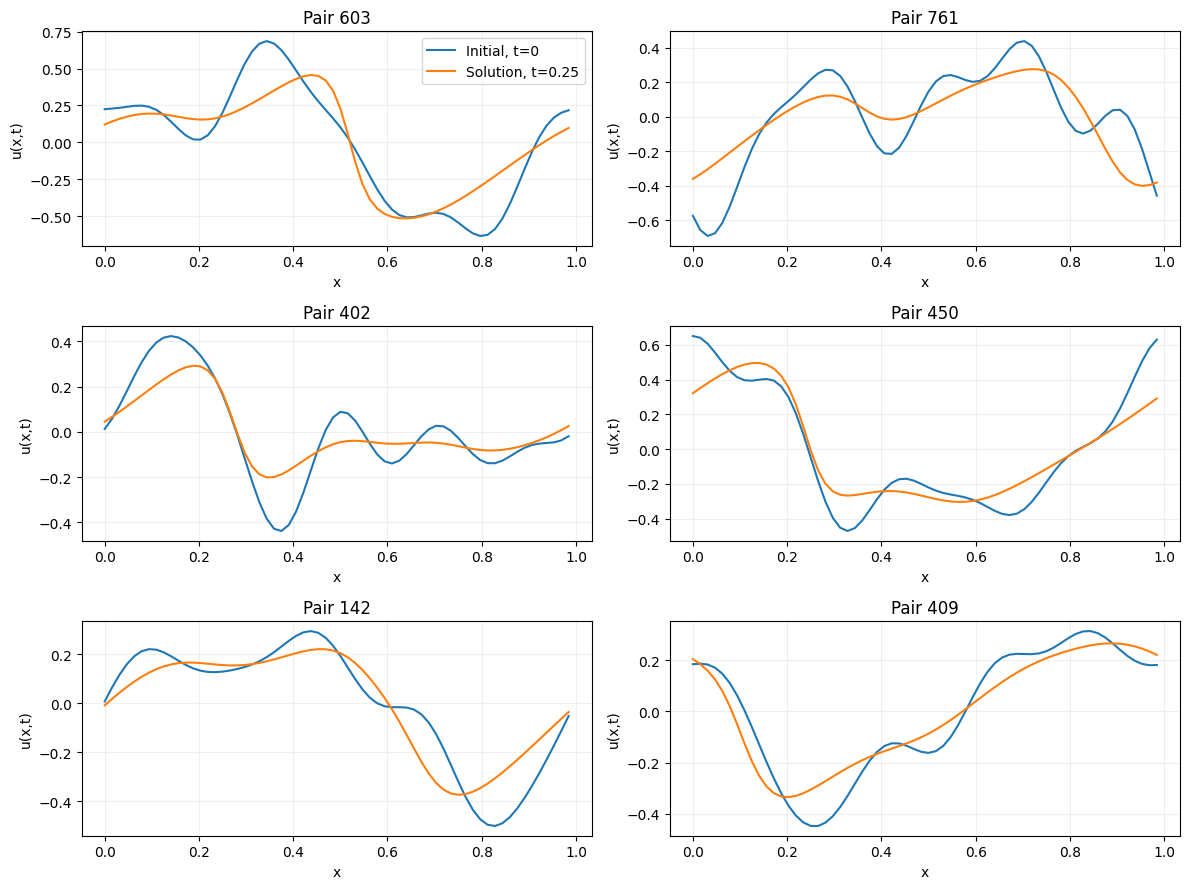

In [5]:
n_examples = 6  # Try 2, 4, 6, or 8
rng = np.random.default_rng(99)
indices = rng.choice(len(X), size=n_examples, replace=False)
ncols = 2
nrows = (n_examples + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3*nrows), squeeze=False)
for ax, i in zip(axes.flat, indices):
    ax.plot(x, X[i], label='Initial, t=0')
    ax.plot(x, Y[i], label='Solution, t=0.25')
    ax.set(title=f'Pair {i}', xlabel='x', ylabel='u(x,t)')
    ax.grid(alpha=0.2)
for ax in axes.flat[n_examples:]:
    ax.axis('off')
axes.flat[0].legend()
fig.tight_layout()
plt.show()

## 4. See many functions at once

A heatmap uses one row per function and one column per spatial location. This is *not* a time series: each row represents a different random initial condition.

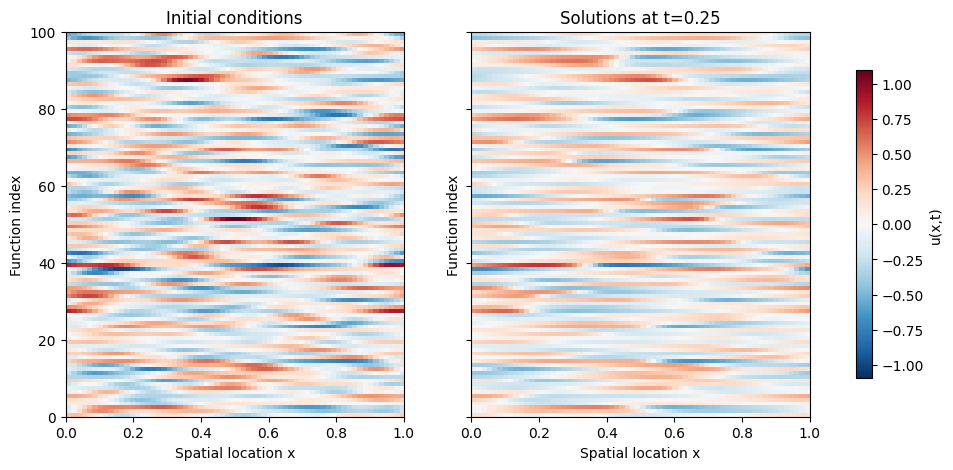

In [6]:
n_heatmap = 100  # Try up to 800
limit = np.max(np.abs(np.concatenate([X[:n_heatmap], Y[:n_heatmap]])))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, values, title in zip(axes, (X, Y), ('Initial conditions', 'Solutions at t=0.25')):
    im = ax.imshow(values[:n_heatmap], aspect='auto', origin='lower',
                   extent=(0, 1, 0, n_heatmap), cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set(title=title, xlabel='Spatial location x', ylabel='Function index')
fig.colorbar(im, ax=axes, label='u(x,t)', shrink=0.8)
plt.show()

## 5. Compare Fourier frequency content

Viscosity damps spatial variation, while the nonlinear term can create new frequencies. We can inspect this by averaging squared Fourier magnitudes across the training functions.

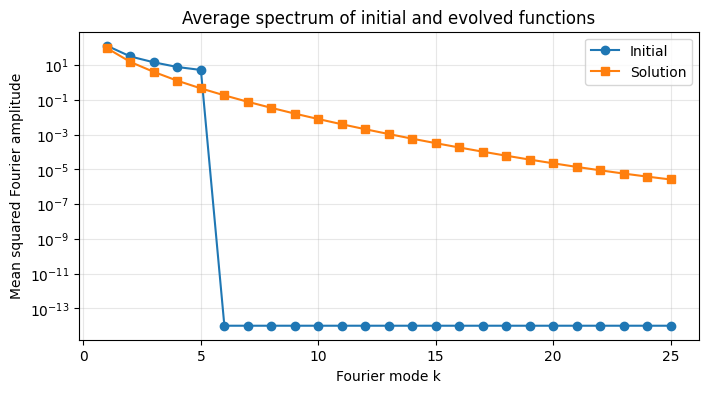

In [7]:
freq = np.fft.rfftfreq(len(x), d=1/len(x))
power_initial = np.mean(np.abs(np.fft.rfft(X, axis=1))**2, axis=0)
power_solution = np.mean(np.abs(np.fft.rfft(Y, axis=1))**2, axis=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(freq[1:26], power_initial[1:26] + 1e-14, 'o-', label='Initial')
ax.semilogy(freq[1:26], power_solution[1:26] + 1e-14, 's-', label='Solution')
ax.set(xlabel='Fourier mode k', ylabel='Mean squared Fourier amplitude',
       title='Average spectrum of initial and evolved functions')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 6. Make your own initial condition (optional)

Edit the five sine/cosine coefficients or the final time. This calls the *same finite-volume solver* that generated the dataset. It is an exploratory new simulation and does **not** modify the saved training, validation, or test files.

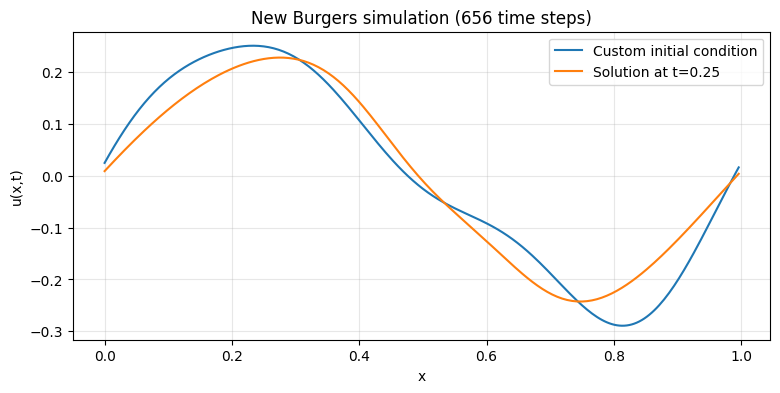

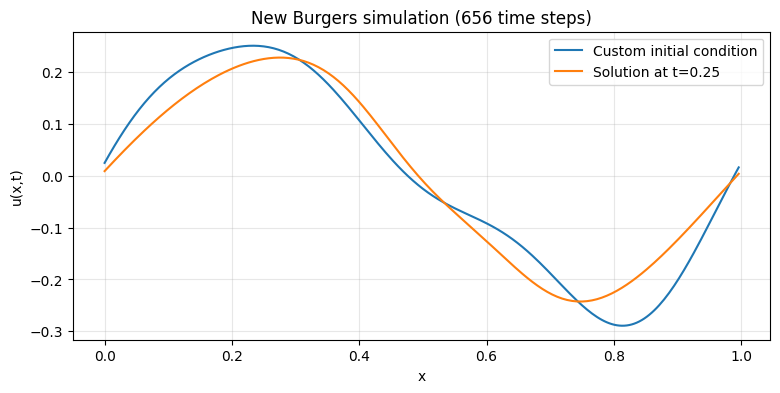

In [12]:
from operator_baselines import make_initial_conditions, solve_burgers

a_custom = np.array([[1.0, 0.4, 0.0, 0.0, 0.0]])  # Five sine coefficients
b_custom = np.array([[0.0, 0.0, 0.3, 0.0, 0.0]])  # Five cosine coefficients
viscosity = 0.01
final_time = 0.25

u0 = make_initial_conditions(a_custom, b_custom, n_grid=256, amplitude=0.25)
uT, steps = solve_burgers(u0, viscosity, final_time)
xx = np.arange(256) / 256
plt.figure(figsize=(9, 4))
plt.plot(xx, u0[0], label='Custom initial condition')
plt.plot(xx, uT[0], label=f'Solution at t={final_time}')
plt.xlabel('x')
plt.ylabel('u(x,t)')
plt.title(f'New Burgers simulation ({steps} time steps)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()